# Lab 10-01 · Diodes and Diode Circuits

Companion to [chapter 10-01](../../chapters/10-01-diodes-and-diode-circuits.md). Each part states a prediction to make before running it. The `assert` lines check the results against the chapter's and this lab's answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import lambertw
from scipy.integrate import solve_ivp

VT = 1.380649e-23 * 300 / 1.602176634e-19   # 25.852 mV
IS = 1e-15                                     # the course diode
print(f"V_T = {VT*1e3:.3f} mV")

V_T = 25.852 mV


## Part 1 · Solving one diode

*Predict first:* from which starting voltages will Newton's method overshoot the answer of Example 10-01.1 (5 V, 4.3 kΩ)?

root finding: V_D = 0.714231 V, I_D = 0.996690 mA;  Lambert W: I_D = 0.996690 mA
fixed point: ['0.714317', '0.714231', '0.714231', '0.714231']


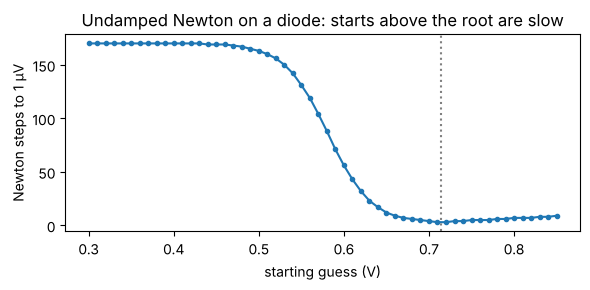

In [2]:
V, R = 5.0, 4.3e3
f  = lambda v: IS * math.expm1(v / VT) - (V - v) / R
fp = lambda v: IS / VT * math.exp(v / VT) + 1 / R
vd = brentq(f, 0, 1, xtol=1e-15)
iw = VT / R * lambertw(R * IS / VT * math.exp((V + R * IS) / VT)).real - IS
print(f"root finding: V_D = {vd:.6f} V, I_D = {(V-vd)/R*1e3:.6f} mA;  Lambert W: I_D = {iw*1e3:.6f} mA")
assert abs(vd - 0.7142) < 5e-5 and abs((V - vd) / R * 1e3 - 0.9967) < 5e-5

# fixed-point iteration from 0.7 V
x, fp_steps = 0.7, []
for _ in range(4):
    x = VT * math.log((V - x) / R / IS + 1); fp_steps.append(x)
print("fixed point:", [f"{s:.6f}" for s in fp_steps])

# Newton steps needed to reach 1 uV, against the starting guess
starts = np.linspace(0.3, 0.85, 56)
steps = []
for s in starts:
    x, n = s, 0
    while abs(x - vd) > 1e-6 and n < 200:
        x -= f(x) / fp(x); n += 1
    steps.append(n)
plt.figure(figsize=(6, 3))
plt.plot(starts, steps, "o-", ms=3)
plt.axvline(vd, color="0.5", ls=":")
plt.xlabel("starting guess (V)"); plt.ylabel("Newton steps to 1 µV")
plt.title("Undamped Newton on a diode: starts above the root are slow")
plt.tight_layout(); plt.show()

Starts *below* the root converge in a handful of steps. Starts *above* it begin where the exponential is huge: the first step lands far below the root and the iteration then climbs back, or (for starts high enough) the exponential overflows. Simulators limit the voltage step for exactly this reason.

## Part 2 · A real peak rectifier

*Predict first:* replacing the 0.7 V constant drop by an exponential diode ($I_S$ = 10 nA, $n$ = 1.9), will the ripple and the peak diode current of Example 10-01.4 rise or fall?

/home/user/.venv-ee/lib/python3.13/site-packages/scipy/integrate/_ivp/radau.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  multiplier = h_abs / h_abs_old * (error_norm_old / error_norm) ** 0.25


exponential: ripple 0.3644 V, mean 11.0489 V, peak i_D 370.6 mA
constant drop (exact): ripple 0.3780 V, peak i_D 540.3 mA
formula: ripple 0.4007 V


500 ohm, constant drop: ripple 0.7312 V (1.93x), peak 752 mA (1.39x)


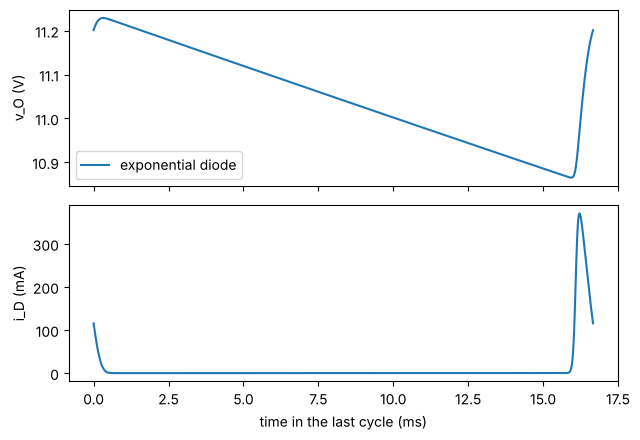

In [3]:
f60, T = 60.0, 1 / 60.0
w = 2 * math.pi * f60

def simulate(iD_of, R, C=470e-6, cycles=4, v0=11.15):
    rhs = lambda t, y: [(iD_of(t, y[0]) - y[0] / R) / C]
    sol = solve_ivp(rhs, (0, cycles * T), [v0], method="Radau", max_step=T / 4000, rtol=1e-10, atol=1e-12,
                    dense_output=True)
    tt = np.linspace((cycles - 1) * T, cycles * T, 100001)
    vv = sol.sol(tt)[0]
    ii = np.array([iD_of(t, y) for t, y in zip(tt, vv)])
    return tt, vv, ii

src = lambda t: 12.0 * math.cos(w * t)
exp_diode = lambda t, v: 10e-9 * math.expm1((src(t) - v) / (1.9 * VT))
def cd_diode(Ron):
    return lambda t, v: max(0.0, (src(t) - 0.7 - v) / Ron)

tt, ve, ie = simulate(exp_diode, 1e3)
res = {}
for Ron in (2e-4, 1e-4):
    _, vc, ic = simulate(cd_diode(Ron), 1e3)
    res[Ron] = (vc.max() - vc.min(), ic.max())
rip_cd = 2 * res[1e-4][0] - res[2e-4][0]; ipk_cd = 2 * res[1e-4][1] - res[2e-4][1]
print(f"exponential: ripple {ve.max()-ve.min():.4f} V, mean {ve.mean():.4f} V, peak i_D {ie.max()*1e3:.1f} mA")
print(f"constant drop (exact): ripple {rip_cd:.4f} V, peak i_D {ipk_cd*1e3:.1f} mA")
print(f"formula: ripple {11.3/(60*1e3*470e-6):.4f} V")
assert abs((ve.max() - ve.min()) - 0.364) < 5e-4 and abs(ve.mean() - 11.05) < 5e-3 and abs(ie.max() * 1e3 - 371) < 0.5
assert abs(rip_cd - 0.378) < 5e-4

res5 = {}
for Ron in (2e-4, 1e-4):
    _, vc, ic = simulate(cd_diode(Ron), 500.0, v0=11.3)
    res5[Ron] = (vc.max() - vc.min(), ic.max())
rip5 = 2 * res5[1e-4][0] - res5[2e-4][0]; ipk5 = 2 * res5[1e-4][1] - res5[2e-4][1]
print(f"500 ohm, constant drop: ripple {rip5:.4f} V ({rip5/rip_cd:.2f}x), peak {ipk5*1e3:.0f} mA ({ipk5/ipk_cd:.2f}x)")
assert abs(rip5 - 0.731) < 5e-4 and abs(ipk5 * 1e3 - 752) < 0.5

fig, ax = plt.subplots(2, 1, figsize=(6.5, 4.5), sharex=True)
ax[0].plot((tt - tt[0]) * 1e3, ve, label="exponential diode")
ax[0].set_ylabel("v_O (V)"); ax[0].legend()
ax[1].plot((tt - tt[0]) * 1e3, ie * 1e3); ax[1].set_ylabel("i_D (mA)"); ax[1].set_xlabel("time in the last cycle (ms)")
plt.tight_layout(); plt.show()

## Part 3 · The Zener regulator

Sweep the supply and the load for Example 10-01.6 (56 Ω, $V_{Z0}$ = 4.757 V, $r_z$ = 7 Ω). Below dropout the Zener is off, and the output is $V_S - RI_L$.

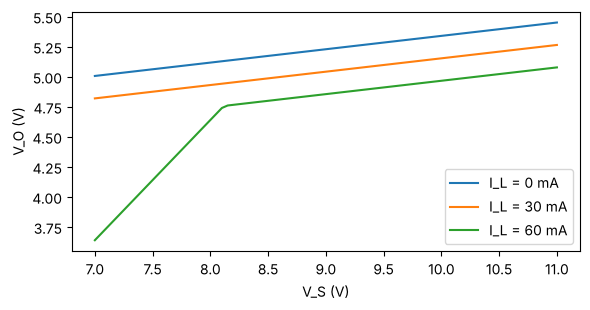

dropout at 60 mA: 8.117 V;  V_O(10 V, 50 mA) = 5.0284 V
load step 0 to 50 mA at 9 V: Zener 311 mV, 0.2-ohm shunt reference 9.96 mV


In [4]:
VZ0, rz, R = 4.757, 7.0, 56.0
def vo(VS, IL, VZ0=VZ0, rz=rz):
    v_on = (rz * VS + R * VZ0 - R * rz * IL) / (R + rz)
    return v_on if v_on > VZ0 else VS - R * IL      # Zener off: plain resistor
VSs = np.linspace(7, 11, 81)
plt.figure(figsize=(6, 3.2))
for IL in (0, 0.03, 0.06):
    plt.plot(VSs, [vo(s, IL) for s in VSs], label=f"I_L = {IL*1e3:.0f} mA")
plt.xlabel("V_S (V)"); plt.ylabel("V_O (V)"); plt.legend(); plt.tight_layout(); plt.show()
dropout = VZ0 + R * 0.06
print(f"dropout at 60 mA: {dropout:.3f} V;  V_O(10 V, 50 mA) = {vo(10, 0.05):.4f} V")
assert abs(dropout - 8.12) < 5e-3 and abs(vo(10, 0.05) - 5.028) < 5e-4
print(f"load step 0 to 50 mA at 9 V: Zener {1e3*(vo(9,0)-vo(9,0.05)):.0f} mV, 0.2-ohm shunt reference "
      f"{1e3*(vo(9,0,2.495,0.2)-vo(9,0.05,2.495,0.2)):.2f} mV")

## Part 4 · Limiter, clamp and doubler

The limiter's transfer curve (two back-to-back course diodes, 1 kΩ), and the clamp and doubler of Example 10-01.7 simulated from switch-on (5 V peak, 1 kHz, 1 µF capacitors, diodes as 0.7 V drops with 1 Ω on-resistance).

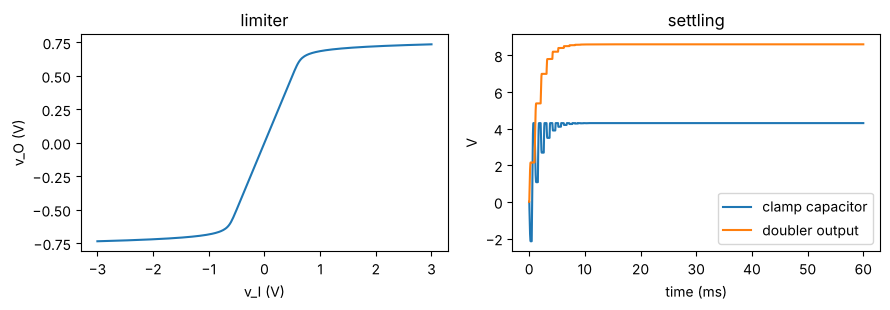

after 60 cycles: clamp capacitor 4.300 V, doubler 8.600 V


In [5]:
vin = np.linspace(-3, 3, 301)
vout = [brentq(lambda x: 2 * IS * math.sinh(x / VT) - (v - x) / 1e3, -abs(v) - 1e-9, abs(v) + 1e-9) if v else 0.0
        for v in vin]
fq, Vp, Cc, Ron = 1e3, 5.0, 1e-6, 1.0
def rhs(t, y):
    vc1, vc2 = y
    vx = Vp * math.sin(2 * math.pi * fq * t) - vc1
    i1 = max(0.0, (-0.7 - vx) / Ron); i2 = max(0.0, (vx - 0.7 - vc2) / Ron)
    return [(i2 - i1) / Cc, i2 / Cc]
sol = solve_ivp(rhs, (0, 60 / fq), [0, 0], method="Radau", max_step=1 / fq / 2000, rtol=1e-8, atol=1e-10,
                dense_output=True)
t = np.linspace(0, 60 / fq, 30001); y = sol.sol(t)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(vin, vout); ax[0].set_xlabel("v_I (V)"); ax[0].set_ylabel("v_O (V)"); ax[0].set_title("limiter")
ax[1].plot(t * 1e3, -y[0], label="clamp capacitor"); ax[1].plot(t * 1e3, y[1], label="doubler output")
ax[1].set_xlabel("time (ms)"); ax[1].set_ylabel("V"); ax[1].legend(); ax[1].set_title("settling")
plt.tight_layout(); plt.show()
print(f"after 60 cycles: clamp capacitor {-y[0][-1]:.3f} V, doubler {y[1][-1]:.3f} V")
assert abs(-y[0][-1] - 4.3) < 0.05 and abs(y[1][-1] - 8.6) < 0.05